1. Дослідження даних, розбиття та масштабування

Дані завантажуються, цільова змінна перетворюється у векторний формат (One-Hot), а сам датасет ділиться на три незалежні частини: тестову, валідаційну та тренувальну

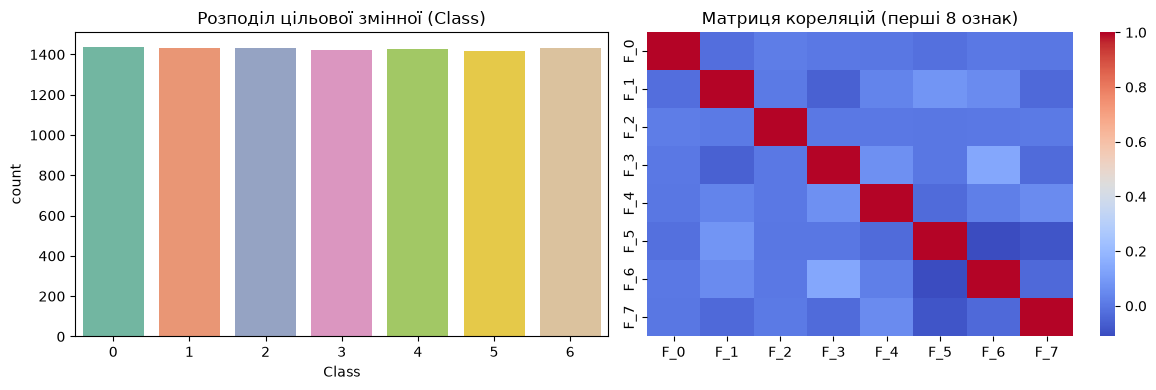

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, log_loss, confusion_matrix
from sklearn.datasets import make_classification

# 1. Завантаження даних (синтетичний набір для прикладу)
X, y = make_classification(n_samples=10000, n_features=16, n_informative=10, n_classes=7, random_state=42)
df = pd.DataFrame(X, columns=[f'F_{i}' for i in range(16)])
df['Class'] = y

# --- Exploratory Data Analysis (EDA) ---
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
# ВИПРАВЛЕНО: додано hue='Class' та legend=False для уникнення FutureWarning
sns.countplot(x='Class', hue='Class', data=df, palette='Set2', legend=False)
plt.title("Розподіл цільової змінної (Class)")

plt.subplot(1, 2, 2)
sns.heatmap(df.iloc[:, :8].corr(), annot=False, cmap='coolwarm')
plt.title("Матриця кореляцій (перші 8 ознак)")
plt.tight_layout()
plt.show()
# ---------------------------------------

def one_hot_encode(y, num_classes):
    return np.eye(num_classes)[y]

num_classes = len(np.unique(y))
y_ohe = one_hot_encode(y, num_classes)

# 2. Розбиття на множини (Global Test 20%, Global Val 15%, FL Train Pool 65%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y_ohe, test_size=0.20, stratify=y, random_state=42)
X_fl_train, X_val, y_fl_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1875, stratify=np.argmax(y_temp, axis=1), random_state=42
)

# 3. Масштабування
scaler = StandardScaler()
X_fl_train_scaled = scaler.fit_transform(X_fl_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

StandardScaler обчислює математичне сподівання та стандартне відхилення ознак виключно на основі X_fl_train, після чого віднімає середнє і ділить на відхилення для всіх вибірок. stratify гарантує, що пропорції 7 класів у кожній вибірці залишаться однаковими.
Розбиття даних до масштабування запобігає витоку даних (Data Leakage). Якщо масштабувати весь датасет відразу, інформація про тестову вибірку неявно вплине на тренування, і фінальні метрики будуть хибно завищеними. Тестова вибірка повинна залишатися абсолютно невідомою для моделі до самого кінця.

2. Реалізація багатокласової логістичної регресії

Створюється клас моделі машинного навчання, який виконує пряме поширення (прогноз), обчислення помилки та зворотне поширення (градієнтний спуск) для багатокласової задачі.

In [32]:
class MulticlassLogisticRegression:
    def __init__(self, n_features, n_classes, lambda_reg=0.01):
        self.W = np.zeros((n_features, n_classes)) 
        self.b = np.zeros((1, n_classes))          
        self.lambda_reg = lambda_reg               
        
    def softmax(self, Z):
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
    
    def predict_proba(self, X):
        return self.softmax(np.dot(X, self.W) + self.b)
    
    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)
    
    def compute_loss(self, X, Y):
        m = X.shape[0]
        P = self.predict_proba(X)
        core_loss = - (1 / m) * np.sum(Y * np.log(P + 1e-15))
        reg_loss = (self.lambda_reg / 2) * np.sum(self.W ** 2)
        return core_loss + reg_loss
    
    def compute_gradients(self, X, Y):
        m = X.shape[0]
        P = self.predict_proba(X)
        dW = (1 / m) * np.dot(X.T, (P - Y)) + self.lambda_reg * self.W
        db = (1 / m) * np.sum(P - Y, axis=0, keepdims=True)
        return dW, db
    
    def fit_mini_batch(self, X, Y, lr=0.01, batch_size=64, epochs=100, X_val=None, Y_val=None):
        m = X.shape[0]
        history = {'train_loss': [], 'val_loss': []}
        for epoch in range(epochs):
            indices = np.arange(m)
            np.random.shuffle(indices)
            X_shuffled, Y_shuffled = X[indices], Y[indices]
            for i in range(0, m, batch_size):
                X_batch, Y_batch = X_shuffled[i:i+batch_size], Y_shuffled[i:i+batch_size]
                dW, db = self.compute_gradients(X_batch, Y_batch)
                self.W -= lr * dW
                self.b -= lr * db
            history['train_loss'].append(self.compute_loss(X, Y))
            if X_val is not None:
                history['val_loss'].append(self.compute_loss(X_val, Y_val))
        return history

Замість циклів for по кожному прикладу використовуються матричні операції (векторизація) через np.dot. Функція softmax перетворює сирі логіти у ймовірності, що в сумі дають 1. Градієнт $\frac{\partial J}{\partial W}$ рахується як матричний добуток транспонованої матриці $X$ та різниці між прогнозом і реальністю.
Для чого це потрібно: Це базовий рушій, який дозволить кожному клієнту локально оновлювати власні ваги. Ridge (L2) регуляризація застосовується тільки до ваг $W$, щоб запобігти перенавчанню, тоді як зміщення $b$ залишається нерегуляризованим, оскільки воно відповідає лише за базовий зсув класів.

3. Центрально навчана базова модель

Модель тренується на повному пулі тренувальних даних FL Train Pool, так, ніби вони зберігаються в одному місці.
Модель проходить через дані 150 епох, коригуючи ваги, після чого обчислюються класичні метрики: accuracy, macro-F1, balanced accuracy та log-loss.

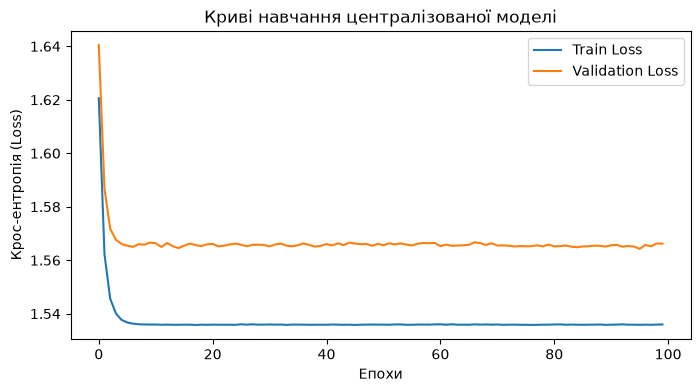

In [26]:
central_model = MulticlassLogisticRegression(
    n_features=X_fl_train_scaled.shape[1], n_classes=num_classes, lambda_reg=0.01
)

# Навчання з відстеженням Train та Validation Loss
hist_central = central_model.fit_mini_batch(
    X_fl_train_scaled, y_fl_train, lr=0.1, batch_size=128, epochs=100,
    X_val=X_val_scaled, Y_val=y_val
)

# --- ДОДАНО: Графік навчання централізованої моделі ---
plt.figure(figsize=(8, 4))
plt.plot(hist_central['train_loss'], label='Train Loss')
plt.plot(hist_central['val_loss'], label='Validation Loss')
plt.title("Криві навчання централізованої моделі")
plt.xlabel("Епохи")
plt.ylabel("Крос-ентропія (Loss)")
plt.legend()
plt.show()
# ------------------------------------------------------

y_pred_central = central_model.predict(X_test_scaled)

Централізована модель слугує базовою лінією (baseline) для порівняння. У федеративному навчанні якість глобальної моделі майже завжди нижча за централізовану через неоднорідність даних та клієнтський дрейф. Цей етап встановлює теоретичний максимум якості для нашого датасету.

4. Розподіл даних (IID та Non-IID)

Єдиний масив даних розрізається на $K$ частин, щоб зімітувати локальні пристрої користувачів.

Це імітує реальні умови Federated Learning, де дані є Non-IID (незалежні та однаково нерозподілені). Сервер не має доступу до цих сирих даних, він побачить лише ваги після їх локального навчання.

In [33]:
K = 5 # Кількість клієнтів

def split_data_dirichlet(X, y, num_clients, alpha=0.3):
    n_classes = y.shape[1]
    client_data = [([], []) for _ in range(num_clients)]
    y_labels = np.argmax(y, axis=1)
    
    for c in range(n_classes):
        idx_c = np.where(y_labels == c)[0]
        np.random.shuffle(idx_c)
        
        # Розподіл Діріхле для моделювання неоднорідних даних
        proportions = np.random.dirichlet([alpha] * num_clients)
        proportions = np.cumsum(proportions) * len(idx_c)
        splits = np.split(idx_c, proportions.astype(int)[:-1])
        
        for k in range(num_clients):
            if len(splits[k]) > 0:
                client_data[k][0].extend(X[splits[k]])
                client_data[k][1].extend(y[splits[k]])
                
    return [(np.array(cd[0]), np.array(cd[1])) for cd in client_data]

# Створення розбиття з сильною неоднорідністю
clients_non_iid = split_data_dirichlet(X_fl_train_scaled, y_fl_train, K, alpha=0.3)

Розподіл Діріхле при малому параметрі $\alpha=0.3$ генерує різкі, асиметричні пропорції (наприклад, 80% даних класу йде одному клієнту, а інші отримують майже нуль). Далі масиви індексів розщеплюються за цими пропорціями.

5. Симуляція федеративного навчання (FedAvg)

Зважування гарантує, що клієнти з великими датасетами роблять більший внесок у глобальну модель. Без зважування клієнт із 10 прикладами сильно б спотворив загальну модель.

In [34]:
def fed_avg_simulation(clients_data, n_features, n_classes, rounds=20, local_epochs=5):
    global_model = MulticlassLogisticRegression(n_features, n_classes)
    val_loss_history = []
    
    for r in range(rounds):
        local_weights_W, local_weights_b, n_samples = [], [], []
        
        # Локальне навчання клієнтів
        for k in range(len(clients_data)):
            X_k, Y_k = clients_data[k]
            n_k = X_k.shape[0]
            if n_k == 0: continue
            
            local_model = MulticlassLogisticRegression(n_features, n_classes)
            local_model.W = np.copy(global_model.W)
            local_model.b = np.copy(global_model.b)
            
            local_model.fit_mini_batch(X_k, Y_k, lr=0.05, batch_size=32, epochs=local_epochs)
            
            local_weights_W.append(local_model.W)
            local_weights_b.append(local_model.b)
            n_samples.append(n_k)
            
        # Агрегація ваг на сервері (FedAvg)
        total_samples = sum(n_samples)
        global_model.W = sum((n / total_samples) * w for n, w in zip(n_samples, local_weights_W))
        global_model.b = sum((n / total_samples) * b for n, b in zip(n_samples, local_weights_b))
        
        # Моніторинг процесу на Global Validation
        val_loss_history.append(global_model.compute_loss(X_val_scaled, y_val))
        
    return global_model, val_loss_history

# Запуск симуляції
global_noniid, hist_noniid = fed_avg_simulation(
    clients_non_iid, X_fl_train_scaled.shape[1], num_classes, rounds=30, local_epochs=5
)

Сервер і клієнти обмінюються вагами протягом кількох комунікаційних раундів.
Кожен клієнт бере глобальні ваги, робить кілька кроків градієнтного спуску на своїх даних і відправляє нові матриці назад. Сервер сумує ці матриці, множачи кожну на вагу клієнта.

6. Дослідження ефектів та візуалізація



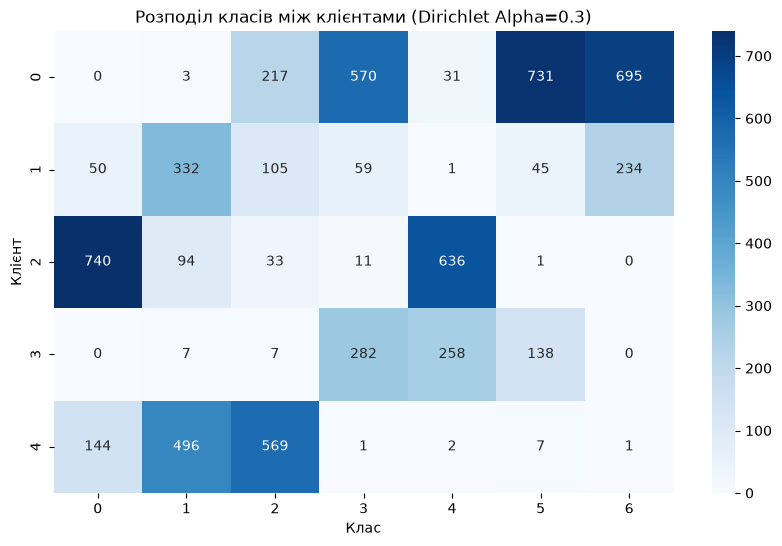

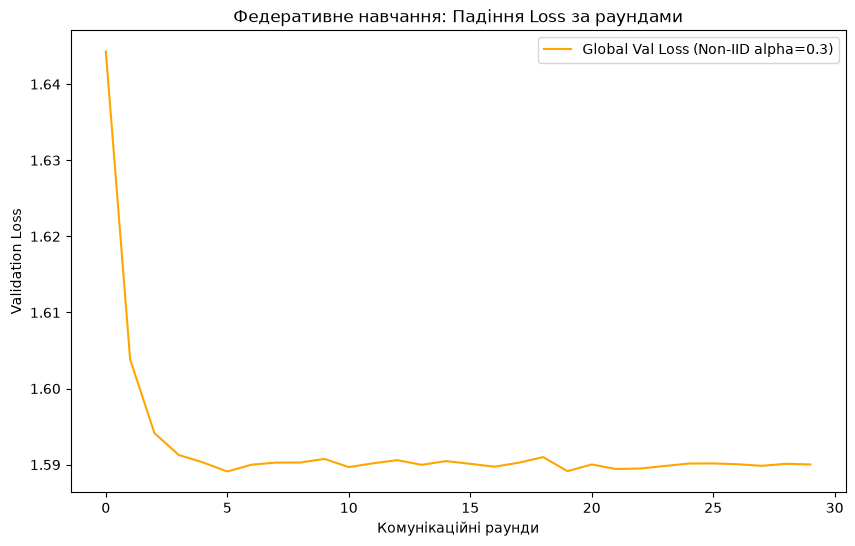


=== Порівняльна таблиця результатів ===
        Model Type Alpha  Accuracy  Macro-F1
       Centralized   N/A    0.4195  0.418146
Federated (FedAvg)   5.0    0.4145  0.413223
Federated (FedAvg)   1.0    0.4140  0.408706
Federated (FedAvg)   0.3    0.3895  0.362740


In [35]:
# 1. Візуалізація розподілу класів між клієнтами
dist_matrix = np.zeros((K, num_classes))
for k, (Xc, Yc) in enumerate(clients_non_iid):
    dist_matrix[k] = np.sum(Yc, axis=0)

plt.figure(figsize=(10, 6))
sns.heatmap(dist_matrix, annot=True, fmt='g', cmap='Blues')
plt.title("Розподіл класів між клієнтами (Dirichlet Alpha=0.3)")
plt.xlabel("Клас")
plt.ylabel("Клієнт")
plt.show()

# 2. Графік збіжності Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(hist_noniid, label='Global Val Loss (Non-IID alpha=0.3)', color='orange')
plt.title("Федеративне навчання: Падіння Loss за раундами")
plt.xlabel("Комунікаційні раунди")
plt.ylabel("Validation Loss")
plt.legend()
plt.show()

# 3. Дослідження впливу неоднорідності (Експеримент 1) та побудова таблиці
results = []
results.append({
    'Model Type': 'Centralized',
    'Alpha': 'N/A',
    'Accuracy': accuracy_score(y_true_test, y_pred_central),
    'Macro-F1': f1_score(y_true_test, y_pred_central, average='macro')
})

alphas = [5.0, 1.0, 0.3]
for a in alphas:
    clients_dist = split_data_dirichlet(X_fl_train_scaled, y_fl_train, K, alpha=a)
    global_mod, _ = fed_avg_simulation(clients_dist, X_fl_train_scaled.shape[1], num_classes, rounds=20, local_epochs=5)
    
    y_pred_fl = global_mod.predict(X_test_scaled)
    results.append({
        'Model Type': 'Federated (FedAvg)',
        'Alpha': a,
        'Accuracy': accuracy_score(y_true_test, y_pred_fl),
        'Macro-F1': f1_score(y_true_test, y_pred_fl, average='macro')
    })

df_results = pd.DataFrame(results)
print("\n=== Порівняльна таблиця результатів ===")
print(df_results.to_string(index=False))

Будується теплова карта розбиття даних та лінійний графік падіння функції втрат. Також оцінюється фінальна точність глобальної моделі.
np.sum(Yc, axis=0) обчислює суму по стовпцях One-Hot матриць, показуючи точну кількість зразків кожного класу в кожного клієнта.

7. Додатковий експеримент: Персоналізація

In [36]:
def personalize_models(global_model, clients_data, lr=0.05, epochs=2):
    personalized_models = []
    for k in range(len(clients_data)):
        X_k, Y_k = clients_data[k]
        if X_k.shape[0] == 0: continue
            
        pers_model = MulticlassLogisticRegression(global_model.W.shape[0], global_model.b.shape[1])
        pers_model.W = np.copy(global_model.W)
        pers_model.b = np.copy(global_model.b)
        
        # Донавчання на локальних даних клієнта
        pers_model.fit_mini_batch(X_k, Y_k, lr=lr, batch_size=32, epochs=epochs)
        personalized_models.append(pers_model)
        
    return personalized_models

personalized_clients = personalize_models(global_noniid, clients_non_iid, epochs=2)

X_c0, y_c0 = clients_non_iid[0]
y_true_c0 = np.argmax(y_c0, axis=1)

acc_global = accuracy_score(y_true_c0, global_noniid.predict(X_c0))
acc_pers = accuracy_score(y_true_c0, personalized_clients[0].predict(X_c0))

print(f"Точність Глобальної моделі на Клієнті 0: {acc_global:.4f}")
print(f"Точність Персоналізованої моделі на Клієнті 0: {acc_pers:.4f}")

Точність Глобальної моделі на Клієнті 0: 0.4014
Точність Персоналізованої моделі на Клієнті 0: 0.5656


Після того, як федеративне навчання завершено, глобальна модель розсилається клієнтам, і кожен з них донавчає її на власному локальному датасеті.
Створюються локальні копії global_model, для яких викликається fit_mini_batch лише на 2 епохи. Потім порівнюється, наскільки краще персоналізована модель прогнозує дані конкретного клієнта порівняно зі "спільною" глобальною моделлю.